In [2]:
!pip install wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 5.0 MB/s eta 0:00:003.5 MB/s eta 0:00:01


In [3]:
import re
import matplotlib.pyplot as plt
import pandas as pd
from wordcloud import STOPWORDS, WordCloud


In [6]:
# Load dataset (update path to your local CSV)
df = pd.read_csv("Dataset-SA.csv")

# Standardize column names if your CSV uses Title Case or alternate names
rename_map = {
    "product_price": "price",
    "Rate": "rating",
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

# Clean rating: convert to numeric and keep valid 1.0 - 5.0 scale
df["rating_clean"] = pd.to_numeric(df["rating"], errors="coerce")
df["rating_clean"] = df["rating_clean"].where(
    (df["rating_clean"] >= 1.0) & (df["rating_clean"] <= 5.0)
)
df["price_clean"] = (
    df["price"]
    .astype(str)
    .pipe(lambda s: pd.to_numeric(s, errors="coerce"))
)

In [7]:
items = (
    df.dropna(subset=["product_name"])
    .groupby("product_name", as_index=False)
    .agg(
        mean_rating=("rating_clean", "mean"),
        mean_price=("price_clean", "mean"),
        review_count=("Summary", "count"),
    )
    .round({"mean_rating": 2, "mean_price": 2})
)

print(items.head(10))

                                        product_name  mean_rating  mean_price  \
0  1170BLBR Unique New Day  Date Analog Watch   F...         3.99       299.0   
1  288SDTL TIMEWEAR Silver Pink Dial Stainless St...         4.41       339.0   
2       38024PP25 Minimalists Analog Watch   For Men         4.89       850.0   
3  3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...         3.67       417.0   
4  3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...         4.75       199.0   
5              77085PP03 Volt Analog Watch   For Men         4.71       699.0   
6  7SEVEN Airtel DTH Remote Airtel Xstream Remote...         4.69       219.0   
7   ADONYX Combo of Knee,Palm, Elbow & Ankle Support         3.80       199.0   
8  ADZOY Metal Lazy Stand Bracket for Neck Rest o...         3.52       284.0   
9  AGAMI Green 2 Layer Lucky Bamboo plant with Bi...         4.46       279.0   

   review_count  
0           150  
1           376  
2             9  
3           100  
4            28  


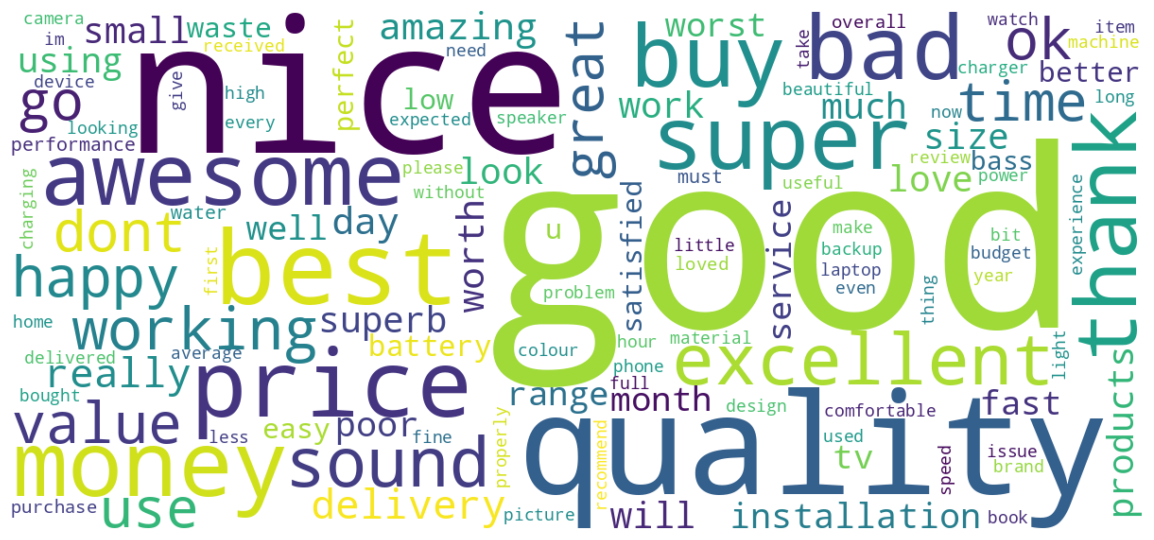

In [8]:
# Combine non-null review summaries and normalize text
corpus = " ".join(df["Summary"].dropna().astype(str)).lower()
corpus = re.sub(r"[^a-z\s]", " ", corpus)

# Add domain-generic words if needed so product attributes stand out
stopwords = STOPWORDS.union({"product", "flipkart", "one", "get", "got"})

wordcloud = WordCloud(
    width=1200,
    height=550,
    background_color="white",
    stopwords=stopwords,
    collocations=False,
    max_words=120,
).generate(corpus)

plt.figure(figsize=(12, 5.5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.tight_layout()
plt.show()